# Régression Linéaire (Prédiction du gain)

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from dotenv import load_dotenv

load_dotenv()
DATA_DIR = os.getenv("DATA_DIR")

df = pd.read_csv(os.path.join(DATA_DIR, "univariateLinearRegression.csv"))
print(len(df))
print(df.head())
print(df.describe())

96
   6.1101   17.592
0  5.5277   9.1302
1  8.5186  13.6620
2  7.0032  11.8540
3  5.8598   6.8233
4  8.3829  11.8860
          6.1101     17.592
count  96.000000  96.000000
mean    8.181151   5.716709
std     3.884451   5.404947
min     5.026900  -2.680700
25%     5.690950   1.952550
50%     6.735950   4.455300
75%     8.639925   6.879150
max    22.203000  24.147000


In [2]:
X = df.iloc[0:len(df), 0]   # population (column 0)
Y = df.iloc[0:len(df), 1]   # profit (column 1)

### Q3) Visualisation des données (nuage de points)

Le nuage de points représente le profit (×10 000 $) en fonction de la population de la ville (×10 000 habitants), pour 97 villes.

**Interprétation :**
- **Tendance croissante** : plus la population est grande, plus le profit est élevé → relation **positive** entre X et Y.
- **Forme approximativement linéaire** : les points suivent globalement une droite, ce qui justifie un modèle de **régression linéaire** $F(x) = ax + b$.
- **Concentration des données** : la majorité des villes ont entre 50 000 et 90 000 habitants (X ≈ 5 à 9), avec des profits entre −3 et 8. Les grandes villes (X > 15) sont rares (≈ 6 points), donc les prédictions dans cette zone sont moins fiables.
- **Dispersion croissante** : l'écart autour de la tendance augmente avec la population (profits entre 17 et 24 pour X ≈ 19–22) ; la population n'explique pas à elle seule tout le profit.
- **Profits négatifs** : quelques petites villes (X ≈ 5–6,5) présentent des pertes (jusqu'à ≈ −2,7), ce qui suggère qu'un camion n'est pas rentable en dessous d'une certaine taille de population.
- **Valeurs atypiques** : certaines villes moyennes (X ≈ 7–9) ont des profits élevés (≈ 12–14), bien au-dessus de la tendance.

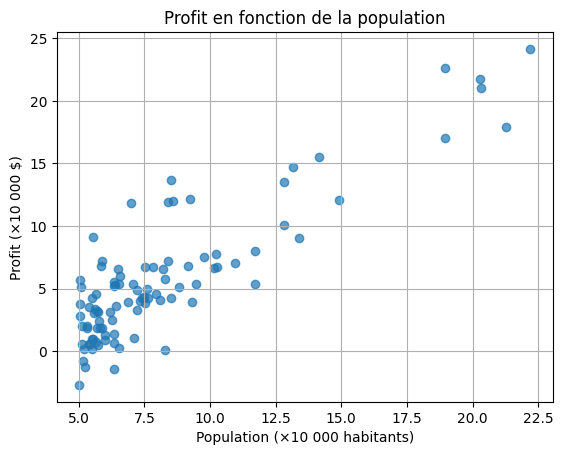

In [3]:
plt.scatter(X, Y, alpha=0.7)
plt.xlabel('Population (×10 000 habitants)')
plt.ylabel('Profit (×10 000 $)')
plt.title('Profit en fonction de la population')
plt.grid(True)
plt.show()

### la régression linéaire à une variable (univariée

a (slope)     = 1.2135
b (intercept) = -4.2115
r = 0.8722   R² = 0.7607


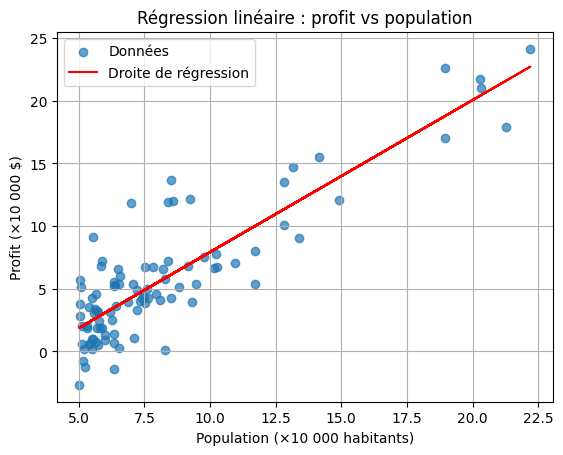

Profit prédit pour 20.27 : 20.38709883129834


In [ ]:
# Régression linéaire univariée (moindres carrés)
slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y)
#linregress() renvoie plusieurs variables de retour. On s'interesse au slope(a) et intercept(b) 
print(f"a (slope)     = {slope:.4f}")
print(f"b (intercept) = {intercept:.4f}")
print(f"r = {r_value:.4f}   R² = {r_value**2:.4f}")

def F(x):
    return slope * x + intercept

# Droite de régression sur le nuage de points
fitLine = F(X)
plt.scatter(X, Y, alpha=0.7, label='Données')
plt.plot(X, fitLine, c='r', label='Droite de régression')
plt.xlabel('Population (×10 000 habitants)')
plt.ylabel('Profit (×10 000 $)')
plt.title('Régression linéaire : profit vs population')
plt.legend(); plt.grid(True); plt.show()

# Prédiction pour une population de 20.27
print("Profit prédit pour 20.27 :", F(20.27))